In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [73]:
data=pd.read_csv("farm_yield_400_plots.csv")
data

,District,Plot_ID,Rainfall_mm,Fertiliser_kg_ha,Temperature_C,Soil_Quality,Yield_t_ha
0,River Plains,RIV-001,774.37,138.68,25.86,8.57,8.40
1,River Plains,RIV-002,787.14,95.14,29.08,6.88,7.49
2,River Plains,RIV-003,921.26,127.45,27.58,7.23,7.79
3,River Plains,RIV-004,753.09,155.25,26.69,8.23,9.02
4,River Plains,RIV-005,1052.95,105.93,27.25,7.84,8.02
...,...,...,...,...,...,...,...
395,Eastern Hills,EAS-096,575.07,168.68,24.43,5.49,7.24
396,Eastern Hills,EAS-097,691.38,163.62,26.05,5.55,7.68
397,Eastern Hills,EAS-098,632.62,47.30,24.89,6.03,7.22
398,Eastern Hills,EAS-099,870.68,180.63,25.17,5.86,7.89


In [97]:
dist=data[data['District']=='River Plains']
m=dist['Yield_t_ha'].mean()
print(m)

8.058200000000001


In [98]:
res=(data.groupby('District')['Yield_t_ha'].agg(['mean','std','count']).sort_values("mean",ascending=False))
res.to_csv("Aggregation_Districts.csv")
res

,mean,std,count
District,,,
River Plains,8.0582,1.184594,100
Central Valley,7.7168,1.246842,100
Western Fields,7.3214,1.165386,100
Eastern Hills,6.9773,1.095979,100


In [99]:
data1=data[['Rainfall_mm','Fertiliser_kg_ha','Temperature_C','Soil_Quality']].to_numpy()
data1
x=np.column_stack([
    np.ones(len(data)),
     data1
])
x
y=data['Yield_t_ha'].to_numpy()
print(x.shape)
print(y.shape)
print(x[1])

(400, 5)
(400,)
[  1.   787.14  95.14  29.08   6.88]


In [100]:
coeff,residuals,rank,single=np.linalg.lstsq(x,y,rcond=None)
coeff



array([ 2.83959304e+00,  8.08823063e-04,  1.40674734e-02, -1.12989536e-02,
        4.29656204e-01])

In [101]:
beta=np.linalg.lstsq(x,y,rcond=None)[0]
beta

array([ 2.83959304e+00,  8.08823063e-04,  1.40674734e-02, -1.12989536e-02,
        4.29656204e-01])

In [102]:
f=x@beta

In [103]:
residuals=y-f
res=pd.DataFrame({
    'residuals':residuals
})
res

,residuals
0,-0.406761
1,0.047909
2,-0.382418
3,0.152814
4,-0.222019
...,...
395,-0.520403
396,-0.110771
397,0.893742
398,-0.428218


In [104]:
s_res=np.sum(residuals**2)
s_res

np.float64(219.7854181998012)

In [105]:
s_tot=np.sum((y-np.mean(y))**2)
s_tot

np.float64(612.4347077499999)

In [106]:
## R square

rs=1-(s_res/s_tot)
print(rs)

0.6411284085984246


In [107]:
res=(data.groupby('District')['Yield_t_ha'].agg(['mean']).sort_values("mean",ascending=False))
res.to_csv("Mean_ditricts.csv")

In [108]:
df=pd.DataFrame(x)
x_line = np.linspace(df.min(), df.max(), 200)
y_line = np.polyval(beta, x_line)

In [109]:
fert=data['Fertiliser_kg_ha']


In [110]:
n, p = x.shape
degrees_freedom = n - p
mse = s_res / degrees_freedom
cov_beta = mse * np.linalg.inv(x.T @ x)
standard_errors = np.sqrt(np.diag(cov_beta))
t_values = beta / standard_errors

In [111]:
coefficient_table = pd.DataFrame({
    'Feature': ['Intercept', 'Rainfall_mm',
                'Fertiliser_kg_ha', 'Temperature_C',
                'Soil_Quality'],
    'Coefficient': beta,
    'Standard Error': standard_errors,
    't-value': t_values
})
coefficient_table.to_csv("Yield_coefficient.csv",index=False)
print(coefficient_table)

            Feature  Coefficient  Standard Error    t-value
0         Intercept     2.839593        0.548451   5.177481
1       Rainfall_mm     0.000809        0.000301   2.691418
2  Fertiliser_kg_ha     0.014067        0.000653  21.548401
3     Temperature_C    -0.011299        0.019188  -0.588844
4      Soil_Quality     0.429656        0.031055  13.835423


In [114]:

fit_results = pd.DataFrame({
    'Actual Yield': y,
    'Fitted Yield': f,
    'Residual': residuals
})
fit_results.to_csv("Fit_Result.csv",index=False)
print(fit_results.head())

   Actual Yield  Fitted Yield  Residual
0          8.40      8.806761 -0.406761
1          7.49      7.442091  0.047909
2          7.79      8.172418 -0.382418
3          9.02      8.867186  0.152814
4          8.02      8.242019 -0.222019


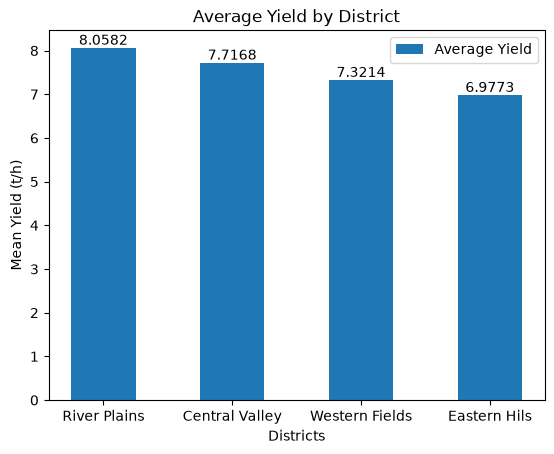

In [90]:
x=[8.0582,7.7168,7.3214,6.9773]
y=['River Plains','Central Valley','Western Fields','Eastern Hils']
bar=plt.bar(y,x,width=0.5,label="Average Yield")
bar
plt.legend()
plt.xlabel("Districts")
plt.ylabel("Mean Yield (t/h)")
plt.title("Average Yield by District")
plt.bar_label(bar)
fig = plt.gcf()
fig.savefig("chart1.jpeg", dpi=120, bbox_inches="tight")
plt.show()

In [91]:
x = data['Fertiliser_kg_ha'].to_numpy()
np.random.seed(40)
yield_values = (
    4 + 0.04 * x - 0.00015 * x**2
    + np.random.normal(0, 1.0, len(x))
)
data['Yield'] = yield_values
beta = np.polyfit(x, yield_values, 2)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = np.polyval(beta, x_line)
a, b, c = beta
peak_x = -b / (2 * a)
peak_y = np.polyval(beta, peak_x)

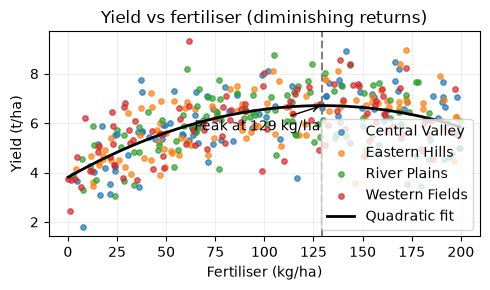

None


In [92]:
plt.figure(figsize=(5, 3))
if 'District' in data.columns:
    for district, group in data.groupby('District'):
        plt.scatter(
            group['Fertiliser_kg_ha'],
            group['Yield'],
            label=district,
            alpha=0.7,
            s=15
        )
else:
    plt.scatter(x, yield_values, label='Actual yield', alpha=0.7)
plt.plot(x_line, y_line, color='black',
         label='Quadratic fit', linewidth=2)
plt.axvline(peak_x, color='gray', linestyle='--')
plt.annotate(
    f'Peak at {peak_x:.0f} kg/ha',
    xy=(peak_x, peak_y),
    xytext=(peak_x - 65, peak_y - 1),
    arrowprops=dict(arrowstyle='->')
)
plt.xlabel('Fertiliser (kg/ha)')
plt.ylabel('Yield (t/ha)')
plt.title('Yield vs fertiliser (diminishing returns)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
fig = plt.gcf()
fig.savefig("chart.jpeg", dpi=120, bbox_inches="tight")
print(plt.show())

             Group  Mean_Fitted  Mean_Residual  Count
0    (5.039, 6.38]     6.008461      -0.150061     50
1     (6.38, 6.74]     6.544984      -0.175584     50
2    (6.74, 7.097]     6.943648       0.125552     50
3   (7.097, 7.444]     7.277774       0.336426     50
4    (7.444, 7.79]     7.648704       0.102296     50
5    (7.79, 8.285]     8.062221      -0.045221     50
6   (8.285, 8.735]     8.520545      -0.041745     50
7  (8.735, 10.191]     9.141064      -0.151664     50


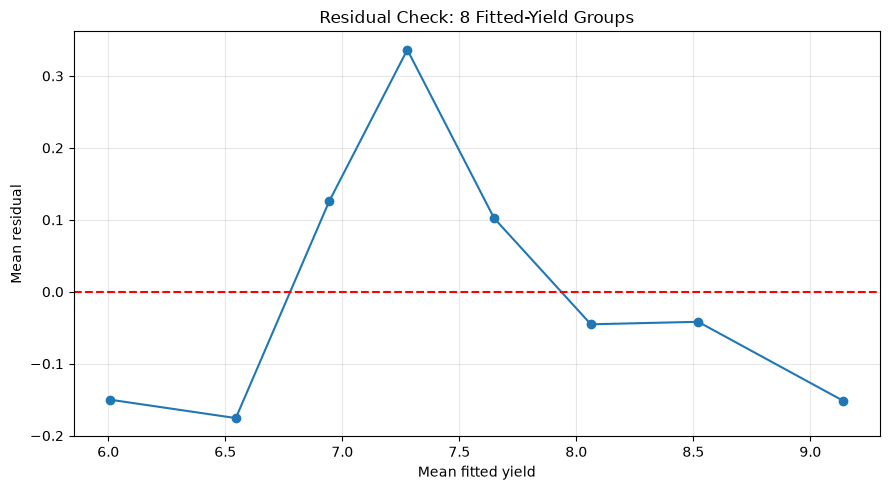

In [93]:
residual_data = pd.DataFrame({
    'Fitted_Yield': f,
    'Residual': residuals
})
residual_data['Group'] = pd.qcut(
    residual_data['Fitted_Yield'],
    q=8,
    duplicates='drop'
)
residual_summary = residual_data.groupby(
    'Group', observed=True
).agg(
    Mean_Fitted=('Fitted_Yield', 'mean'),
    Mean_Residual=('Residual', 'mean'),
    Count=('Residual', 'size')
).reset_index()
print(residual_summary)
plt.figure(figsize=(9, 5))
plt.plot(
    residual_summary['Mean_Fitted'],
    residual_summary['Mean_Residual'],
    marker='o'
)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Mean fitted yield')
plt.ylabel('Mean residual')
plt.title('Residual Check: 8 Fitted-Yield Groups')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
import json
results = {
    "R_squared": float(rs),
    "R_squared_percentage": round(float(rs) * 100, 2),
    "Regression_coefficients": beta.tolist(),
    "Fertiliser_peak_kg_ha": float(peak_x),
    "Predicted_yield_at_peak": float(peak_y)
}
with open("results.json", "w") as file:
    json.dump(results, file, indent=4)
print("Chart saved as chart.png")
print("Results saved as results.json")

Chart saved as chart.png
Results saved as results.json
